In [1]:
import os

for p in ["data/seg_train", "data/seg_train/seg_train", "data/seg_test", "data/seg_test/seg_test"]:
    print(p, "->", os.listdir(p)[:8] if os.path.exists(p) else "YOXDUR")

data/seg_train -> ['seg_train']
data/seg_train/seg_train -> ['forest', 'buildings', 'glacier', 'street', 'mountain', 'sea']
data/seg_test -> ['seg_test']
data/seg_test/seg_test -> ['forest', 'buildings', 'glacier', 'street', 'mountain', 'sea']


In [2]:
train_dir = "data/seg_train/seg_train"
test_dir = "data/seg_test/seg_test"

classes = sorted(os.listdir(train_dir))
print("Siniflər:", classes)
print()

for name, d in [("TRAIN", train_dir), ("TEST", test_dir)]:
    print(name)
    total = 0
    for cls in classes:
        n = len(os.listdir(os.path.join(d, cls)))
        total += n
        print(f"  {cls:10s} {n}")
    print(f"  Cəmi: {total}\n")

Siniflər: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

TRAIN
  buildings  2191
  forest     2271
  glacier    2404
  mountain   2512
  sea        2274
  street     2382
  Cəmi: 14034

TEST
  buildings  437
  forest     474
  glacier    553
  mountain   525
  sea        510
  street     501
  Cəmi: 3000



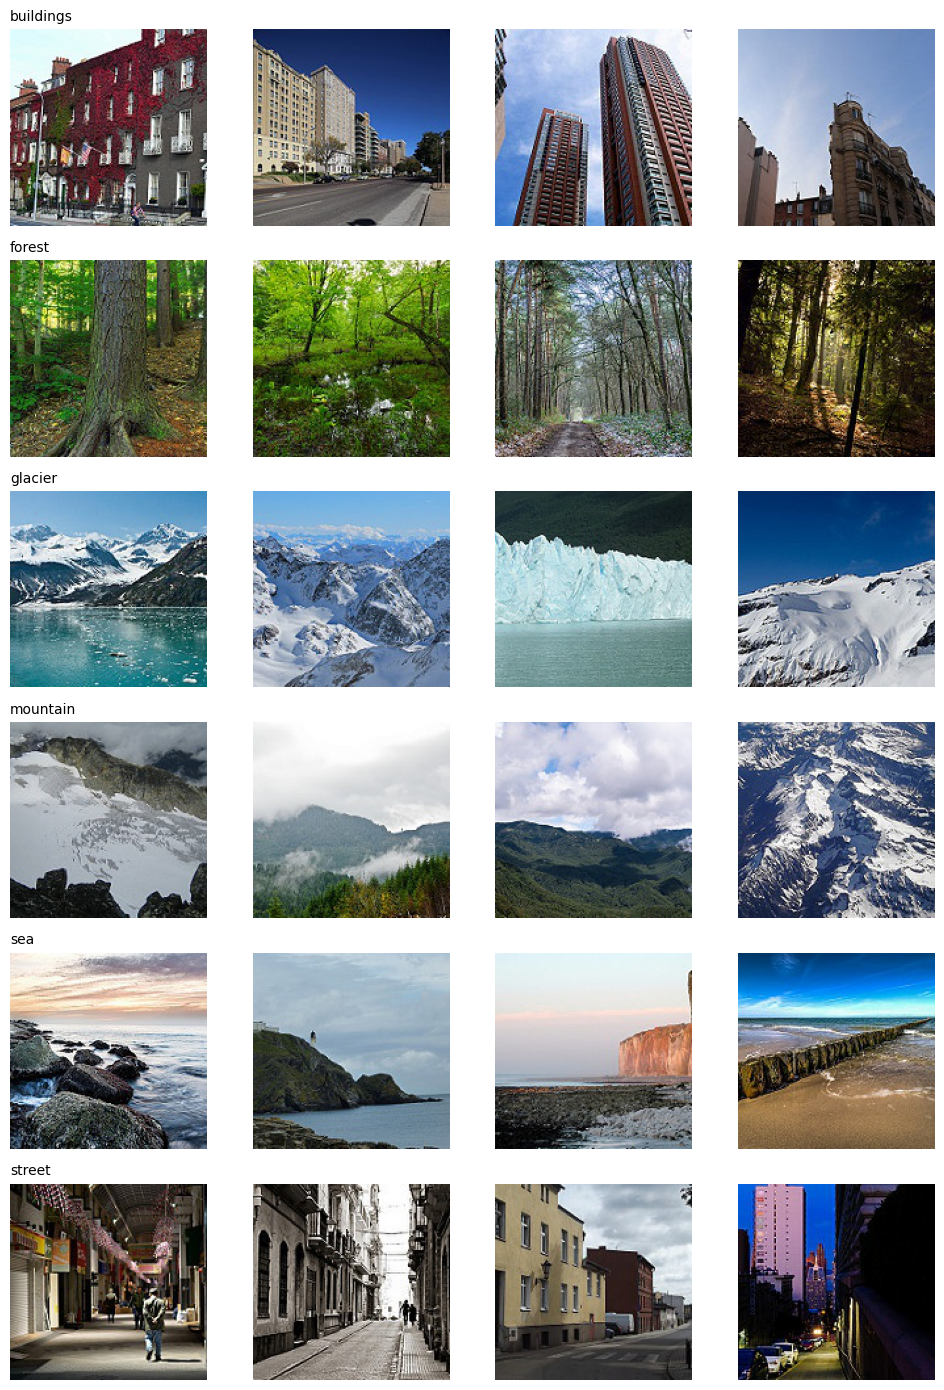

In [3]:
import random
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(len(classes), 4, figsize=(10, 14))
for i, cls in enumerate(classes):
    cls_path = os.path.join(train_dir, cls)
    samples = random.sample(os.listdir(cls_path), 4)
    for j, fname in enumerate(samples):
        axes[i, j].imshow(Image.open(os.path.join(cls_path, fname)))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

In [4]:
from collections import Counter

sizes = Counter()
for cls in classes:
    cls_path = os.path.join(train_dir, cls)
    for fname in random.sample(os.listdir(cls_path), 100):
        sizes[Image.open(os.path.join(cls_path, fname)).size] += 1

print(sizes.most_common(5))

[((150, 150), 598), ((150, 113), 1), ((150, 105), 1)]


In [5]:
import torch
from torchvision import datasets, transforms

IMG_SIZE = 150
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

In [6]:
from torch.utils.data import DataLoader, random_split, Subset

full_train = datasets.ImageFolder(train_dir, transform=train_tf)
full_train_noaug = datasets.ImageFolder(train_dir, transform=eval_tf)

# 85% train, 15% validation
n = len(full_train)
n_val = int(0.15 * n)
generator = torch.Generator().manual_seed(42)
indices = torch.randperm(n, generator=generator).tolist()

val_idx, train_idx = indices[:n_val], indices[n_val:]

train_ds = Subset(full_train, train_idx)        # augmentation ilə
val_ds   = Subset(full_train_noaug, val_idx)    # augmentation olmadan
test_ds  = datasets.ImageFolder(test_dir, transform=eval_tf)

print("Train:", len(train_ds), "| Val:", len(val_ds), "| Test:", len(test_ds))
print("Sinif -> indeks:", full_train.class_to_idx)

Train: 11929 | Val: 2105 | Test: 3000
Sinif -> indeks: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


In [7]:
BATCH_SIZE = 64

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))
print("Batch şəkil formatı:", images.shape)
print("Batch etiket formatı:", labels.shape)
print("Min/Max:", images.min().item(), images.max().item())

Batch şəkil formatı: torch.Size([64, 3, 150, 150])
Batch etiket formatı: torch.Size([64])
Min/Max: -2.1179039478302 2.640000104904175


In [ ]:
import torch.nn as nn

def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)   
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model = SimpleCNN(num_classes=6).to(device)
print(model)

SimpleCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 

In [9]:
x = images.to(device)
out = model(x)
print("Çıxış formatı:", out.shape)   # [64, 6] olmalıdır

n_params = sum(p.numel() for p in model.parameters())
print(f"Parametr sayı: {n_params:,}")

Çıxış formatı: torch.Size([64, 6])
Parametr sayı: 423,046


In [10]:
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

In [11]:
def run_epoch(loader, train: bool):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            out = model(x)
            loss = criterion(out, y)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)

    return total_loss / total, correct / total

In [12]:
import time

EPOCHS = 15
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    scheduler.step(va_loss)

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss)
    history["val_acc"].append(va_acc)

    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), "best_model.pt")
        mark = " <- ən yaxşı, saxlandı"
    else:
        mark = ""

    print(f"Epoch {epoch:2d}/{EPOCHS} | "
          f"train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} | "
          f"{time.time()-t0:.0f}s{mark}")

Epoch  1/15 | train loss 0.960 acc 0.622 | val loss 1.005 acc 0.623 | 43s <- ən yaxşı, saxlandı
Epoch  2/15 | train loss 0.726 acc 0.726 | val loss 1.112 acc 0.609 | 45s
Epoch  3/15 | train loss 0.662 acc 0.753 | val loss 0.517 acc 0.811 | 48s <- ən yaxşı, saxlandı
Epoch  4/15 | train loss 0.615 acc 0.772 | val loss 0.501 acc 0.808 | 61s
Epoch  5/15 | train loss 0.577 acc 0.789 | val loss 0.571 acc 0.774 | 65s
Epoch  6/15 | train loss 0.551 acc 0.801 | val loss 0.508 acc 0.805 | 64s
Epoch  7/15 | train loss 0.536 acc 0.805 | val loss 0.461 acc 0.823 | 63s <- ən yaxşı, saxlandı
Epoch  8/15 | train loss 0.501 acc 0.818 | val loss 0.422 acc 0.847 | 63s <- ən yaxşı, saxlandı
Epoch  9/15 | train loss 0.490 acc 0.824 | val loss 0.414 acc 0.849 | 61s <- ən yaxşı, saxlandı
Epoch 10/15 | train loss 0.472 acc 0.831 | val loss 0.401 acc 0.838 | 65s
Epoch 11/15 | train loss 0.460 acc 0.831 | val loss 0.533 acc 0.787 | 57s
Epoch 12/15 | train loss 0.452 acc 0.839 | val loss 0.394 acc 0.856 | 56s <-

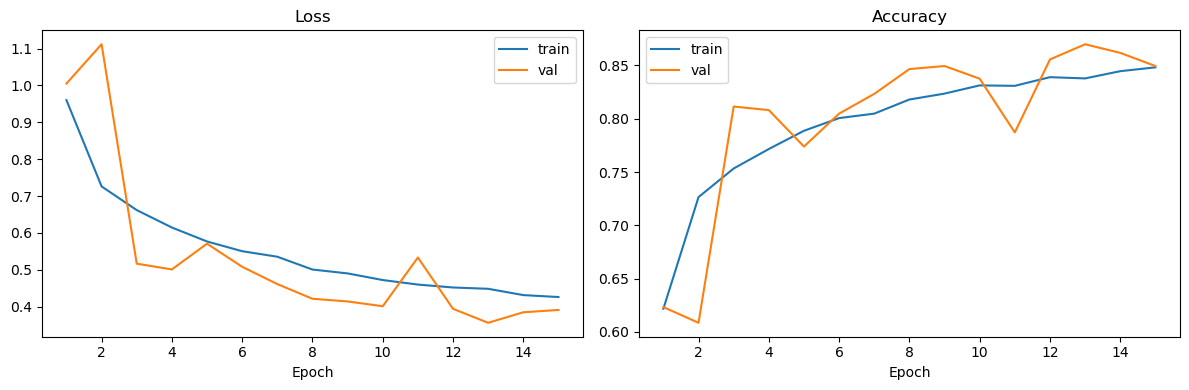

In [13]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, history["train_loss"], label="train")
ax[0].plot(epochs, history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(epochs, history["train_acc"], label="train")
ax[1].plot(epochs, history["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()

plt.tight_layout()
plt.show()

In [14]:
model.load_state_dict(torch.load("best_model.pt", map_location=device))
test_loss, test_acc = run_epoch(test_loader, train=False)
print(f"Test loss: {test_loss:.3f} | Test accuracy: {test_acc:.3f}")

Test loss: 0.400 | Test accuracy: 0.856


/opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


              precision    recall  f1-score   support

   buildings      0.849     0.860     0.855       437
      forest      0.967     0.979     0.973       474
     glacier      0.870     0.741     0.801       553
    mountain      0.850     0.790     0.819       525
         sea      0.750     0.931     0.831       510
      street      0.885     0.856     0.870       501

    accuracy                          0.856      3000
   macro avg      0.862     0.860     0.858      3000
weighted avg      0.861     0.856     0.856      3000



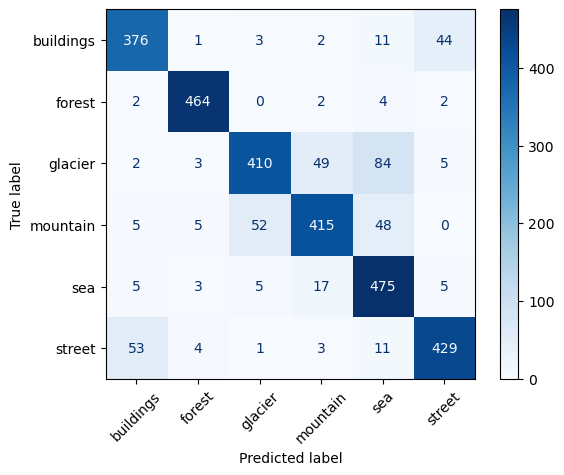

In [15]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_labels.extend(y.numpy())

class_names = full_train.classes
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

cm = confusion_matrix(all_labels, all_preds)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.show()

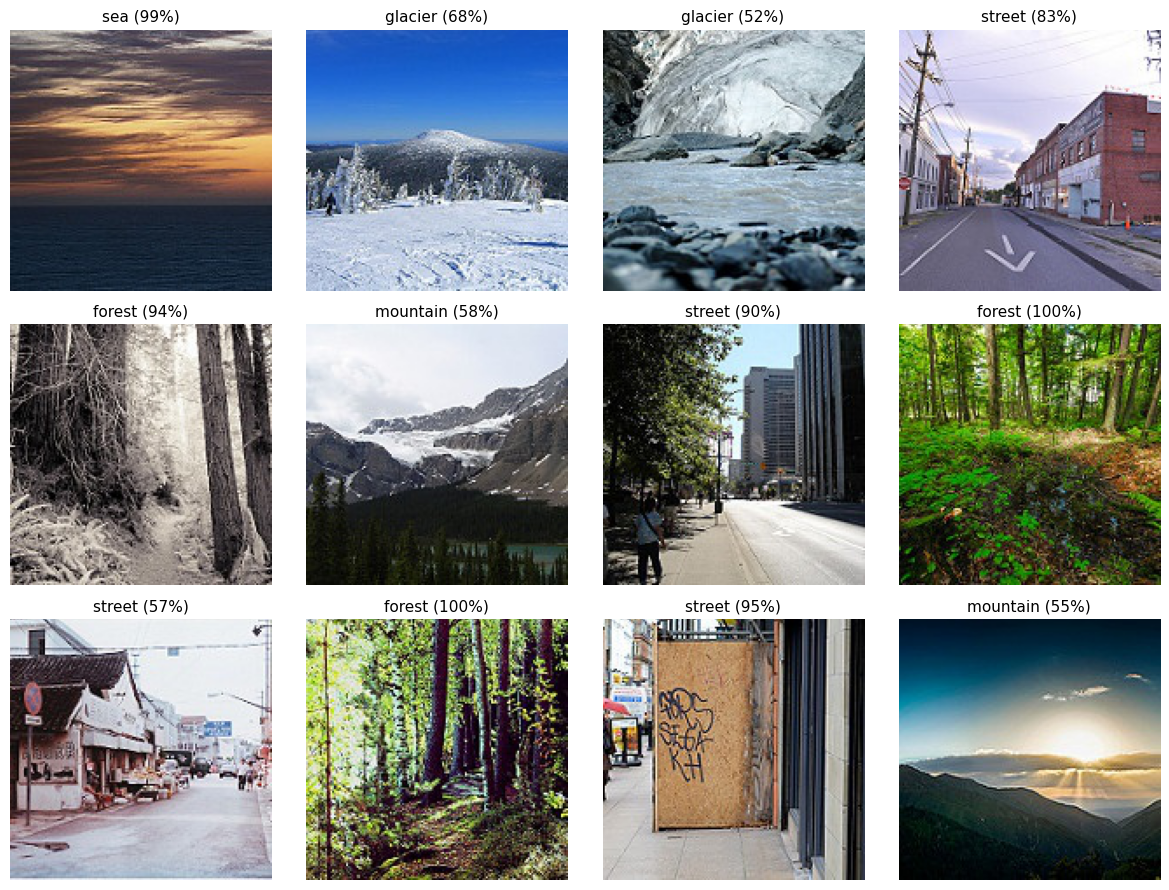

In [16]:
import random
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

pred_dir = "data/seg_pred/seg_pred"   # yol fərqli olarsa düzəlt
class_names = full_train.classes

model.eval()

def predict(img_path):
    img = Image.open(img_path).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = F.softmax(model(x), dim=1)[0]
    conf, idx = probs.max(0)
    return img, class_names[idx.item()], conf.item()

files = random.sample(os.listdir(pred_dir), 12)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, f in zip(axes.flat, files):
    img, label, conf = predict(os.path.join(pred_dir, f))
    ax.imshow(img)
    ax.set_title(f"{label} ({conf:.0%})", fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()

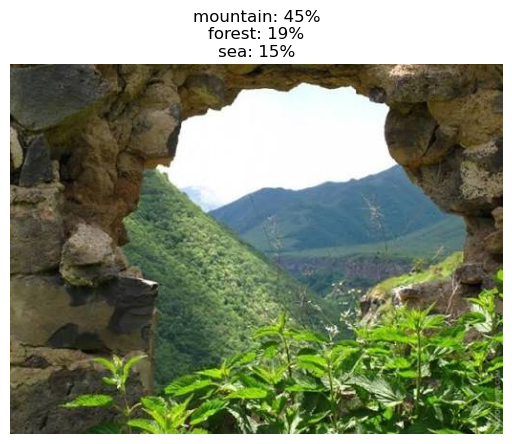

In [17]:
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

img_path = "images.jpeg"
class_names = full_train.classes

model.eval()
img = Image.open(img_path).convert("RGB")
x = eval_tf(img).unsqueeze(0).to(device)

with torch.no_grad():
    probs = F.softmax(model(x), dim=1)[0].cpu()

top = probs.topk(3)
result = [(class_names[i], p.item()) for p, i in zip(top.values, top.indices)]

plt.imshow(img)
plt.title("\n".join(f"{c}: {p:.0%}" for c, p in result))
plt.axis("off")
plt.show()